In [1]:
import casadi as cs
import numpy as np
from matplotlib import pyplot as plt
from time import perf_counter
import pickle
import ctypes
import os

from real_time import Real_Time
from solver_banks import Solver 
from dynamics import Hopper 
import LUT_helper as helper
import display

In [2]:
def initialize_mode(LUT, count, E0, phi_end=1.0):
    return np.column_stack([
        np.asarray(LUT([E0, phi])[:-1]).squeeze()
        for phi in np.linspace(0, phi_end, count)
    ])

In [3]:
def alternating(mode,n,dynamics):
    return tuple(mode if k%2 == 0 else dynamics.next_mode[mode] for k in range(n))

def candidate_sequences(mode, nominal, dynamics, max_modes=4):
    counts = {
        "nominal": nominal, "minus": nominal - 1, "plus": nominal + 1,
    }
    return {
        name: alternating(mode, n, dynamics) for name, n in counts.items() if 1 <= n <= max_modes
    }

def select_candidate(candidates):
    accepted = []
    for candidate in candidates:
        if candidate["success"]:
            accepted.append(candidate)
    return min(accepted, key=lambda c: c["merit"]) if accepted else None

In [4]:
def resample(y, start, end, n):
    old_grid = np.linspace(0.0, 1.0, y.shape[-1])
    new_grid = np.linspace(start, end, n)

    return np.array([
        np.interp(new_grid, old_grid, row)
        for row in np.atleast_2d(y)
    ]).squeeze()

def resample_timed(x, time, count):
    grid = np.linspace(time[0], time[-1], count)
    return np.vstack([
        np.interp(grid, time, row)
        for row in np.asarray(x)
    ])

In [5]:
def shift_trajectory(solution, x0, mode, elapsed): # status: to verify
    idx_m = 0
    while solution["modes"][idx_m] != mode: # status: to verify
        elapsed = max(0.0, elapsed - solution["t"][idx_m]) # status: to verify
        idx_m += 1 # status: to verify

    modes = solution["modes"][idx_m:] 
    x = [xi.copy() for xi in solution["x"][idx_m:]]
    u = [ui.copy() for ui in solution["u"][idx_m:]]
    t = solution["t"][idx_m:].copy()
    elapsed = min(elapsed, max(0.0, t[0] - 1e-2)) # status: to verify
    fraction = elapsed / t[0]
    x[0] = resample(x[0], fraction, 1.0, x[0].shape[1])
    u[0] = resample(u[0], fraction, 1.0, u[0].shape[-1])
    t[0] -= elapsed

    x[0][:, 0] = np.asarray(x0).squeeze()

    
    shifted = {
        "modes": modes,
        "x": x,
        "u": u,
        "t": t,
        "E": solution["E"],
        "phi": solution["phi"],
    }

    return shifted, len(modes)

In [6]:
## Verified chat-gpt generated code

def warm_candidate(shifted, sequence, T, dynamics): # status: to verify
    """Construct the nominal or nominal-minus-one candidate."""
    count = len(sequence)

    candidate = {
        "modes": sequence,
        "x": [x.copy() for x in shifted["x"][:count]],
        "u": [u.copy() for u in shifted["u"][:count]],
        "t": shifted["t"][:count].copy(),
        "E": shifted["E"],
        "phi": shifted["phi"],
    }

    if count < len(shifted["modes"]):
        # The new terminal mode previously ended at an event. Remove its
        # event node so that the terminal trajectory ends inside the mode.
        n_state = candidate["x"][-1].shape[-1]
        end = (n_state - 2) / (n_state - 1)
        candidate["x"][-1] = resample(candidate["x"][-1], 0.0, end, n_state)
        candidate["u"][-1] = resample(candidate["u"][-1], 0.0, end,candidate["u"][-1].shape[-1])
        candidate["t"][-1] *= end # status: to verify

    # Reintegrate the final mode when it absorbs the missing horizon. # status: to verify
    old_duration = candidate["t"][-1] # status: to verify
    new_duration = T - sum(candidate["t"][:-1]) # status: to verify
    if new_duration > old_duration: # status: to verify
        mode = sequence[-1] # status: to verify
        old_grid = np.linspace(0.0, old_duration, candidate["u"][-1].size, endpoint=False) # status: to verify
        new_grid = np.linspace(0.0, new_duration, candidate["u"][-1].size, endpoint=False) # status: to verify
        candidate["u"][-1] = np.interp(new_grid, np.r_[old_grid, old_duration, new_duration], np.r_[candidate["u"][-1], 0.0, 0.0]) # status: to verify
        h = new_duration / (dynamics.N[mode] - 1) # status: to verify
        for k in range(dynamics.N[mode] - 1): # status: to verify
            candidate["x"][-1][:, k+1] = np.asarray(dynamics.rk4[mode](candidate["x"][-1][:, k], h, candidate["u"][-1][k])).squeeze() # status: to verify
    candidate["t"][-1] = new_duration # status: to verify

    return candidate

In [7]:
## WARNING chat-gpt generated

def passive_rollout(x0,m,dynamics,duration):
    x = np.zeros((dynamics.dim[m],dynamics.N[m]))
    x[:,0] = np.asarray(x0).squeeze()
    h = float(duration) / (dynamics.N[m]-1)
    for k in range(dynamics.N[m]-1):
        x[:,k+1] = np.array(dynamics.rk4[m](x[:,k],h,0.0)).squeeze()
    return x


def passive_candidate(shifted, sequence, T,dynamics, terminal_duration=1e-2):
    x = [xi.copy() for xi in shifted["x"]]
    u = [ui.copy() for ui in shifted["u"]]
    duration = shifted["t"].copy()

    current_mode = shifted["modes"][-1]
    next_mode = sequence[-1]
    remaining = T - sum(duration)

    # Continue passively from the end of the warm trajectory to the event.
    event_time, event_trajectory = dynamics.integrate_until_event(x[-1][:, -1], current_mode)
    event_time = event_time.squeeze()
    event_trajectory = np.asarray(event_trajectory)
    passive_duration = float(event_time[-1])

    if passive_duration + terminal_duration > remaining: return None # status: to verify

    # Leave a positive duration for the added terminal mode.
    declared_duration = passive_duration # status: to verify

    # Remesh the enlarged mode, then integrate it instead of interpolating its states. # status: to verify
    old_duration = duration[-1] # status: to verify
    new_duration = old_duration + declared_duration # status: to verify
    old_control_time = np.linspace(0.0, old_duration, u[-1].size, endpoint=False) # status: to verify
    new_control_time = np.linspace(0.0, new_duration, dynamics.N[current_mode])[:-1] # status: to verify
    u[-1] = np.interp(new_control_time, np.r_[old_control_time, old_duration, new_duration], np.r_[u[-1], 0.0, 0.0]) # status: to verify
    x[-1] = np.column_stack([x[-1][:, 0], *[np.zeros(dynamics.dim[current_mode]) for _ in range(dynamics.N[current_mode] - 1)]]) # status: to verify
    h = new_duration / (dynamics.N[current_mode] - 1) # status: to verify
    for k in range(dynamics.N[current_mode] - 1): # status: to verify
        x[-1][:, k+1] = np.asarray(dynamics.rk4[current_mode](x[-1][:, k], h, u[-1][k])).squeeze() # status: to verify
    duration[-1] = new_duration # status: to verify

    # Reset at the remeshed event and propagate the newly added mode. # status: to verify
    state = np.asarray(dynamics.convert[current_mode](x[-1][:, -1])).squeeze() # status: to verify

    final_duration = T - sum(duration)
    x.append(passive_rollout(state, next_mode, dynamics, final_duration,))
    u.append(np.zeros(dynamics.N[next_mode] - 1))
    duration.append(final_duration)

    return {
        "modes": sequence,
        "x": x,
        "u": u,
        "t": duration,
        "E": shifted["E"],
        "phi": shifted["phi"],
    }

def fit_terminal(seed, solver, E_bounds, phi_bounds, count=9): # status: to verify
    mode, x_terminal = seed["modes"][-1], seed["x"][-1][:, -1] # status: to verify
    x_capture = x_terminal[1:] if mode == "f" else x_terminal # status: to verify
    fits = [] # status: to verify
    for E in np.linspace(*E_bounds, count): # status: to verify
        phi = float(np.clip(seed["t"][-1] / float(solver.target([E, 1])[-1]), *phi_bounds)) # status: to verify
        target = np.asarray(solver.target([E, phi])).squeeze() # status: to verify
        target = target[1:-1] if mode == "f" else target[:-1] # status: to verify
        fits.append((np.linalg.norm(target - x_capture), E, phi)) # status: to verify
    _, seed["E"], seed["phi"] = min(fits) # status: to verify
    seed["fit_slack"] = True # status: to verify
    return seed # status: to verify

In [8]:
def qp_data(w,p,linearize,con_min,con_max,w_min,w_max,delta):
    grad,H,A,residual = linearize(w,p)
    nominal = np.asarray(w).squeeze()
    return {
        "h": H, "g": grad, "a": A,
        "lbx": np.maximum(w_min-nominal, -delta),
        "ubx": np.minimum(w_max-nominal, delta),
        "lba": con_min-residual, "uba": con_max-residual,
    }

In [9]:
def RTI_candidate(solver, seed, x0, T, mu):
    p = cs.vertcat(x0,T)
    w_bar = solver.layout.pack(seed["x"],seed["u"],seed["t"],seed["E"],seed["phi"])
    if seed.get("fit_slack", False): # status: to verify
        mode, x_terminal = seed["modes"][-1], seed["x"][-1][:, -1] # status: to verify
        target = np.asarray(solver.target([seed["E"], seed["phi"]])).squeeze() # status: to verify
        residual = (target[1:-1] - x_terminal[1:]) if mode == "f" else (target[:-1] - x_terminal) # status: to verify
        auxiliary = np.r_[seed["E"], seed["phi"], np.maximum(residual, 0.0), np.maximum(-residual, 0.0)] # status: to verify
        w_bar[solver.layout.x_t_slice] = auxiliary # status: to verify
        w_bar[solver.layout.u_t_slice] = auxiliary # status: to verify
    qp = qp_data(
        w_bar, p, solver.linearize,
        solver.con_min, solver.con_max,
        solver.w_min, solver.w_max, solver.delta
    )
    if np.any(qp["lbx"] > qp["ubx"]): return {"success": False} # status: to verify
    qp["x0"] = cs.DM.zeros(solver.layout.nw) 

    result = solve_qp(qp,solver.qp_solver)
    if not solver.qp_solver.stats()["success"]:
        return {"success" : False}

    w = w_bar + result["x"] # alpha = 1
    cost,residual = solver.values(w,p)

    violation = np.maximum(solver.con_min - residual,0) + np.maximum(residual - solver.con_max,0)
    violation_sum = float(cs.sum1(violation))
    return {
        "success": True,
        "w": w,
        "trajectory": solver.layout.unpack(w),
        "cost": float(cost),
        "violation": float(cs.mmax(violation)),
        "merit" : float(cost) + mu * violation_sum
    }

In [10]:
libc = ctypes.CDLL(None)
def solve_qp(qp,solver):
    # wrapper to remove unwanted output from hpipm
    stdout, null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    try:  # CasADi 3.7.2's HPIPM plugin prints directly to C stdout
        os.dup2(null, 1)
        return solver(**qp)
    finally:
        libc.fflush(None)
        os.dup2(stdout, 1)
        os.close(stdout)
        os.close(null)

In [11]:
data = pickle.load(open('../data/dataset_2/dataset_21.pkl','rb'))
K = data["K"]
W = data["W"]
Nf = data["Nf"]
Ns = data["Ns"]
locomotion_NMM = np.array(data["locomotion"][2])
switching_NMM = np.array(data["switch"][2])
Emin = max(min(locomotion_NMM[:,-1]),min(switching_NMM[:,-1]))
Emax = min(max(locomotion_NMM[:,-1]),max(switching_NMM[:,-1]))

dynamics = Hopper(K,W,Nf=15,Ns=20)


In [12]:
E_grid = np.linspace(Emin, Emax, 20)
locomotion_NMM_sampled = helper.energy_sample(locomotion_NMM,E_grid)
switching_NMM_sampled = helper.energy_sample(switching_NMM,E_grid)

phi_grid = np.linspace(0,1,20)
ss_loc,sf_loc = helper.surface(locomotion_NMM_sampled,phi_grid,dynamics)
ss_swi,sf_swi = helper.surface(switching_NMM_sampled,phi_grid,dynamics)

values_sloc = ss_loc.ravel(order="C")
values_floc = sf_loc.ravel(order="C")
values_sswi = ss_swi.ravel(order="C")
values_fswi = sf_swi.ravel(order="C")
LUT_sloc = cs.interpolant('LUT_sloc', 'bspline',[E_grid,phi_grid],values_sloc)
LUT_floc = cs.interpolant('LUT_floc', 'bspline',[E_grid,phi_grid],values_floc)
LUT_sswi = cs.interpolant('LUT_sswi', 'bspline',[E_grid,phi_grid],values_sswi)
LUT_fswi = cs.interpolant('LUT_fswi', 'bspline',[E_grid,phi_grid],values_fswi)

/home/gabin/research/NMM-hopper/SQP/display.py:33: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  frame = ax.legend(fontsize=fontsize,labelcolor=fgColor).get_frame()


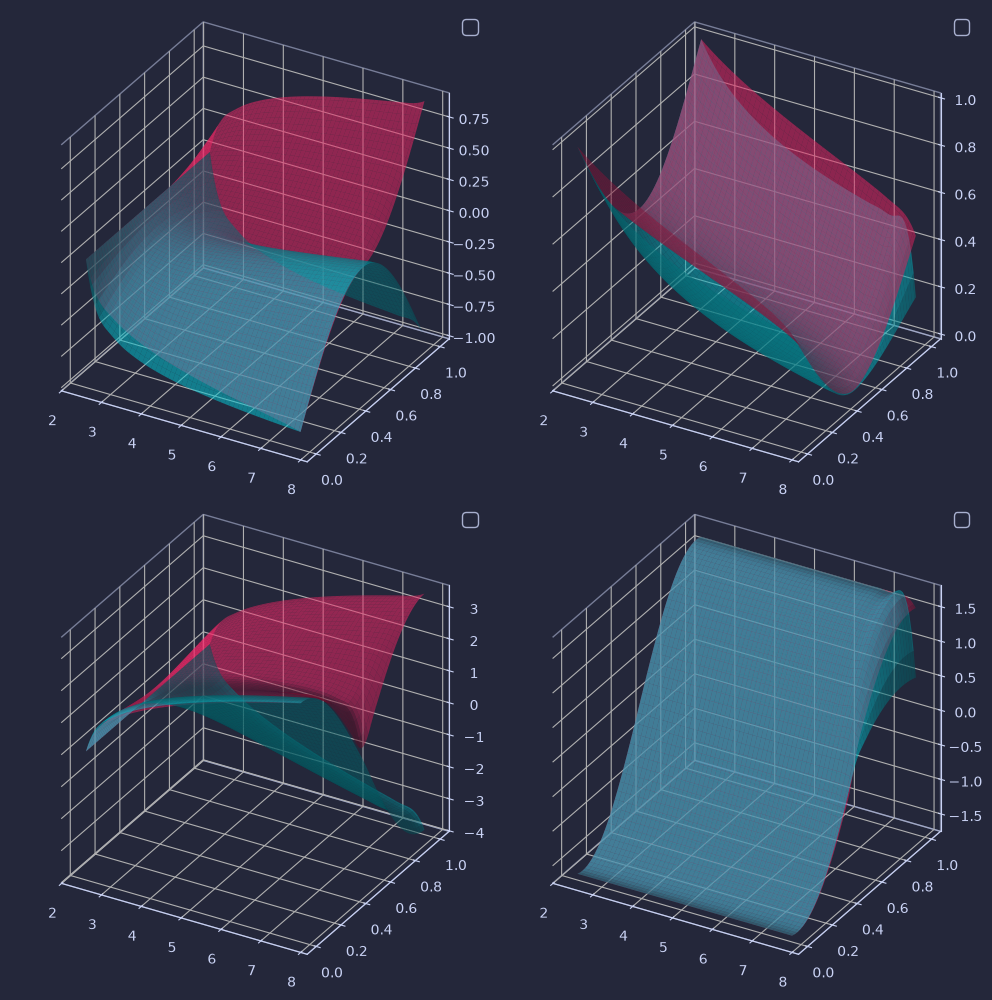

In [13]:
phi_linspace = np.linspace(0,1,100)
E_linspace = np.linspace(Emin,Emax,100)
sloc_fancy = np.zeros((100,100,5))
sswi_fancy = np.zeros((100,100,5))
X1,X2 = np.meshgrid(E_linspace,phi_linspace)
for i in range(100):
    for j in range(100):
        sloc_fancy[i,j] = np.array(LUT_sloc([E_linspace[i],phi_linspace[j]])).squeeze()
        sswi_fancy[i,j] = np.array(LUT_sswi([E_linspace[i],phi_linspace[j]])).squeeze()

fig = plt.figure(figsize=(10,10),facecolor='#24273a')
for row in range(2):
    for column in range(2):
        idx = row*2 + column
        ax = fig.add_subplot(2,2,idx+1,projection='3d')
        ax.set_proj_type('ortho')
        ax.plot_surface(X1,X2,sloc_fancy[:,:,idx].T,alpha=0.55,color='#FF2A6D',zorder=1)
        ax.plot_surface(X1,X2,sswi_fancy[:,:,idx].T,alpha=0.55,color='#05D9E8',zorder=100)
        ax.set_box_aspect((4,4,4))
        display.prettify3D(ax)
plt.tight_layout()
plt.show()


In [14]:
E0 = 4
E_inf = max(Emin,E0-0.2)
E_sup = min(Emax,E0+0.2)

x_bounds = {
    "f" : {1: (0.0, np.inf)}, 
    "s" : {}
}
u_bounds = {
    "f" : (-1,1), 
    "s" : (-1,1)
}
t_bounds = {
    "f": (1e-2, 10.0),
    "s": (1e-2, 10.0),
}
E_bounds = (E_inf,E_sup)
phi_bounds = (0.01,0.99)

violation_limit = 0.5
bounds = (x_bounds, u_bounds, t_bounds, E_bounds, phi_bounds)

In [15]:
sequence_variants = [alternating(m,n,dynamics) for m in 'fs' for n in range(1,5)]
targets = {
    'locomotion': {'f':LUT_floc,'s':LUT_sloc},
    'switching': {'f':LUT_fswi,'s':LUT_sswi}
}
solvers = {
    (name,seq): Solver(LUT[seq[-1]],dynamics,seq,bounds)
    for name,LUT in targets.items() for seq in sequence_variants
}

In [16]:
# Initial passive trajectory: one period + half a stance phase
target_name = "switching"
sequence = ("s", "f", "s")
phi_terminal = 0.5

ts = float(LUT_sloc([E0, 1])[-1])
tf = float(LUT_floc([E0, 1])[-1])
T = ts + tf + phi_terminal * ts

successful = {
    "modes": sequence,
    "x": [
        initialize_mode(LUT_sloc, dynamics.N["s"], E0),
        initialize_mode(LUT_floc, dynamics.N["f"], E0),
        initialize_mode(LUT_sloc, dynamics.N["s"], E0, phi_terminal),
    ],
    "u": [np.zeros(dynamics.N[m] - 1) for m in sequence],
    "t": [ts, tf, phi_terminal * ts],
    "E": E0,
    "phi": phi_terminal,
}

hopper = Real_Time(dynamics, successful["x"][0][:, 0], sequence[0])
elapsed, Ts, mu = 0.0, 5e-2, 2000
plus_cache = None # status: to verify

In [19]:
controller_running = True
iteration = 0
while controller_running and iteration < 30: # status: to verify

    x0,m = hopper.measure()

    shifted,nominal = shift_trajectory(successful, x0, m, elapsed) # status: to verify

    sequences = candidate_sequences(m, nominal, dynamics)

    seeds = {}
    if "nominal" in sequences:
        seed = warm_candidate(shifted, sequences["nominal"], T, dynamics) # status: to verify
        seeds["nominal"] = seed # status: to verify
    if "minus" in sequences:
        seed = warm_candidate(shifted, sequences["minus"], T, dynamics) # status: to verify
        seeds["minus"] = seed # status: to verify
    if "plus" in sequences:
        plus_seed = None # status: to verify
        if plus_cache is not None and m in plus_cache["modes"]: # status: to verify
            cached, _ = shift_trajectory(plus_cache, x0, m, elapsed) # status: to verify
            if tuple(cached["modes"]) == sequences["plus"]: plus_seed = warm_candidate(cached, sequences["plus"], T, dynamics) # status: to verify
        if plus_seed is None: plus_seed = passive_candidate(shifted, sequences["plus"], T, dynamics) # status: to verify
        if plus_seed is not None: seeds["plus"] = fit_terminal(plus_seed, solvers[target_name, sequences["plus"]], E_bounds, phi_bounds) # status: to verify

    candidates = []
    for name,seq in sequences.items():
        if name not in seeds: continue # status: to verify
        solver = solvers[target_name, seq]
        candidate = RTI_candidate(solver, seeds[name], x0, T, mu)
        candidate["name"] = name
        candidate["sequence"] = seq
        candidates.append(candidate)

    cached_plus = next((candidate for candidate in candidates if candidate["name"] == "plus" and candidate["success"]), None) # status: to verify
    plus_cache = cached_plus["trajectory"] if cached_plus is not None else None # status: to verify
    selected = select_candidate(candidates)
    if selected is not None:
        print("success")
        u = selected["trajectory"]["u"][0][0]
        successful = selected["trajectory"]
        elapsed = Ts 
    else: 
        print("no successful trajectory found")
        u = shifted["u"][0][0]
        elapsed += Ts 

    hopper.apply_control(u, Ts)
    iteration += 1

success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
success
